# Model Training & Development

In [7]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, classification_report, roc_auc_score
from xgboost import XGBClassifier, plot_importance

In [9]:
# 1. Properly resolve paths based on current file or working directory
current_dir = Path.cwd()
base_dir = current_dir.parent if current_dir.name == "notebooks" else current_dir
data_dir = base_dir / "data"
db_path = str(data_dir / "deadlock.duckdb")
output_dir = data_dir / "telemetry_timeseries_parquet"

# Build list of specific parquet file paths as strings
parquet_files = [str(output_dir / f"tick_stats_part_{batch_num:04d}.parquet") for batch_num in range(32)]

con = duckdb.connect()

In [11]:
df_model = con.execute(f"""
    WITH match_team_stats AS (
        SELECT 
            match_id,
            team,
            MAX(tick_net_worth) AS final_net_worth,
            MAX(tick_kills) AS total_kills,
            MAX(tick_deaths) AS total_deaths,
            MAX(tick_assists) AS total_assists,
            MAX(player_damage) AS total_player_damage,
            MAX(creep_damage) AS total_creep_damage,
            MAX(boss_damage) AS total_boss_damage,
            
            -- Healing & Sustain aggregates
            SUM(player_healing) AS total_team_player_healing,
            SUM(self_healing) AS total_team_self_healing,
            SUM(damage_absorbed) AS total_team_damage_absorbed,
            
            -- Aim & Accuracy aggregates
            SUM(shots_hit) AS total_team_shots_hit,
            SUM(shots_missed) AS total_team_shots_missed,
            
            MAX(level) AS max_level
        FROM read_parquet(?)
        GROUP BY match_id, team
    ),
    match_features AS (
        SELECT 
            m1.match_id,
            -- Differentials (Team 0 minus Team 1)
            m1.final_net_worth - m2.final_net_worth AS net_worth_diff,
            m1.total_kills - m2.total_kills AS kills_diff,
            m1.total_player_damage - m2.total_player_damage AS damage_diff,
            m1.total_boss_damage - m2.total_boss_damage AS boss_damage_diff,
            m1.max_level - m2.max_level AS level_diff,
            
            -- Healing & Sustain Differentials
            (m1.total_team_player_healing + m1.total_team_self_healing) - 
            (m2.total_team_player_healing + m2.total_team_self_healing) AS sustain_diff,
            
            -- Shooting Accuracy Differential (%)
            (CAST(m1.total_team_shots_hit AS FLOAT) / NULLIF(m1.total_team_shots_hit + m1.total_team_shots_missed, 0)) - 
            (CAST(m2.total_team_shots_hit AS FLOAT) / NULLIF(m2.total_team_shots_hit + m2.total_team_shots_missed, 0)) AS accuracy_diff,
            
            -- Target Label: 1 if Team 0 has higher final net worth, 0 otherwise
            CASE WHEN m1.final_net_worth > m2.final_net_worth THEN 1 ELSE 0 END AS label
        FROM match_team_stats m1
        JOIN match_team_stats m2 ON m1.match_id = m2.match_id AND m1.team != m2.team
        WHERE m1.team = 0
    )
    SELECT * FROM match_features
""", [parquet_files]).df()

df_model = df_model.dropna()

feature_columns = [
    'net_worth_diff', 
    'kills_diff', 
    'damage_diff', 
    'boss_damage_diff', 
    'level_diff',
    'sustain_diff',
    'accuracy_diff'
]

X = df_model[feature_columns]
y = df_model['label']



--- Enhanced Model Performance ---
Accuracy: 99.74%
ROC-AUC:  1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1543
           1       1.00      1.00      1.00      1585

    accuracy                           1.00      3128
   macro avg       1.00      1.00      1.00      3128
weighted avg       1.00      1.00      1.00      3128



<Figure size 1000x600 with 0 Axes>

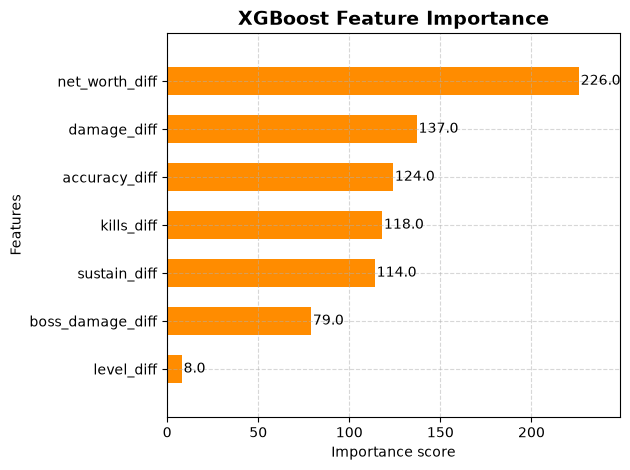

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify  = y
)

model = XGBClassifier(
    n_estimators = 150,
    max_depth = 5,
    learning_rate = 0.08,
    random_state = 42,
    eval_metric = 'logloss'
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"\n--- Enhanced Model Performance ---")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"ROC-AUC:  {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 7. Plot Feature Importances
plt.figure(figsize = (10, 6))
plot_importance(model, color = 'darkorange', height = 0.6)
plt.title('XGBoost Feature Importance', fontsize = 14, fontweight = 'bold')
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()


--- Training Timestamp-Specific XGBoost Models ---

--- Model Performance by Match Timestamp ---
 Minute  Matches  Accuracy (%)  ROC-AUC  Log-Loss
      5    15636         67.04   0.7336    0.6004
     10    15617         71.93   0.8041    0.5308
     15    15364         74.03   0.8353    0.4913
     20    14550         76.15   0.8490    0.4728
     25    12992         77.91   0.8663    0.4500
     30    10604         78.78   0.8806    0.4219
     35     7557         81.88   0.9061    0.3827


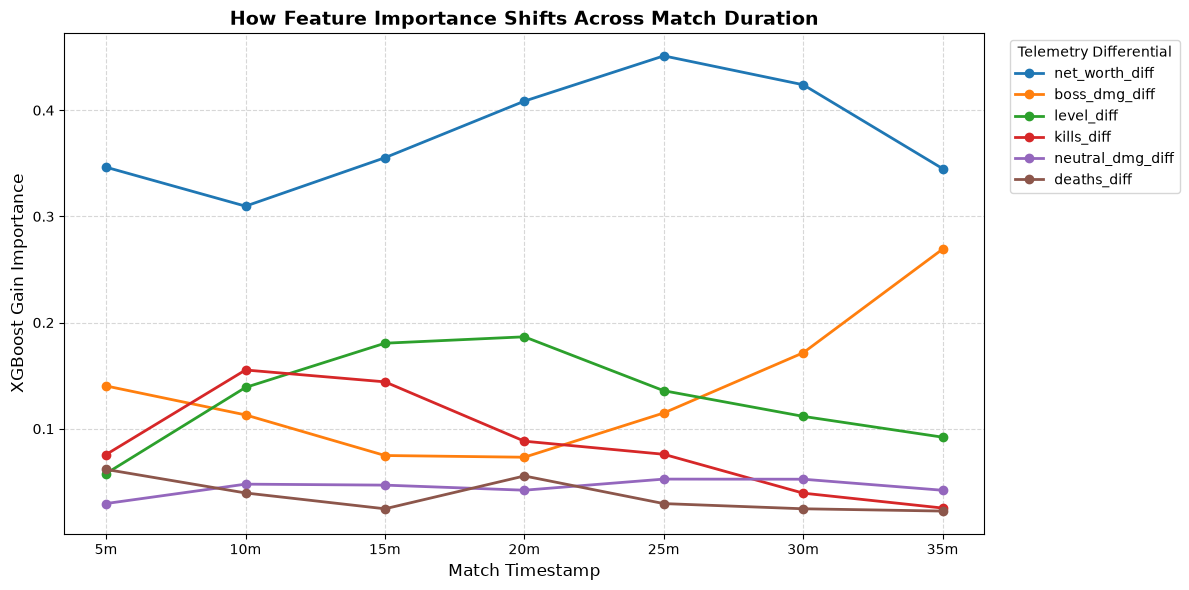

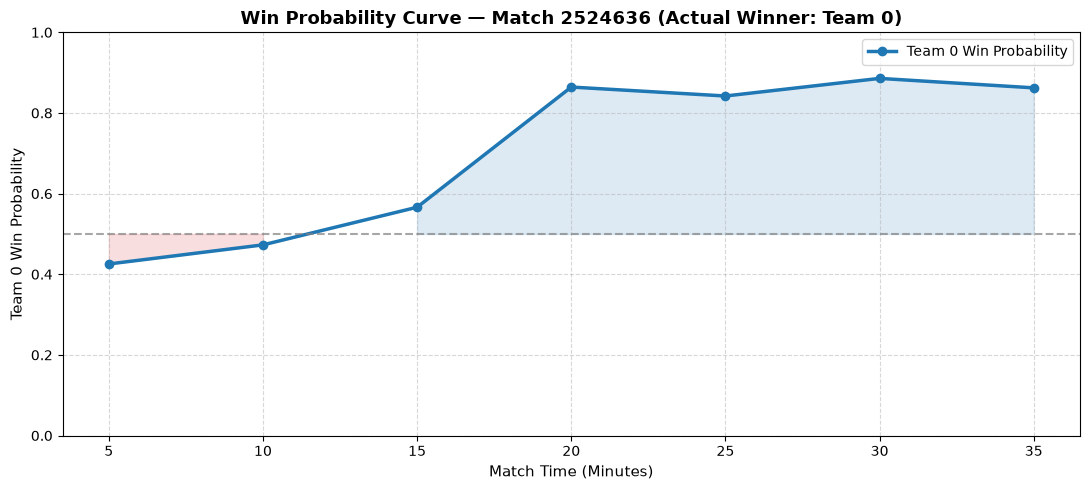

In [16]:
con_ts = duckdb.connect(db_path, read_only = True)

df_ts = con.execute(f"""
    WITH true_outcomes AS (
        SELECT DISTINCT
            m.match_info.match_id AS match_id,
            m.match_info.winning_team AS winning_team
        FROM match_metadata m
        WHERE m.match_info.winning_team IS NOT NULL
    ),
    team_snapshots AS (
        SELECT 
            match_id,
            time_stamp_s,
            team,
            SUM(tick_net_worth) AS net_worth,
            SUM(tick_kills) AS kills,
            SUM(tick_deaths) AS deaths,
            SUM(tick_assists) AS assists,
            SUM(player_damage) AS player_damage,
            SUM(creep_damage) AS creep_damage,
            SUM(neutral_damage) AS neutral_damage,
            SUM(boss_damage) AS boss_damage,
            SUM(denies) AS denies,
            SUM(player_healing + self_healing) AS total_sustain,
            SUM(damage_absorbed) AS damage_absorbed,
            SUM(player_damage_taken) AS damage_taken,
            SUM(shots_hit) AS shots_hit,
            SUM(shots_missed) AS shots_missed,
            SUM(level) AS total_level
        FROM read_parquet(?)
        WHERE time_stamp_s > 0
        GROUP BY match_id, time_stamp_s, team
    )
    SELECT 
        t0.match_id,
        t0.time_stamp_s,
        -- Economic & Objective Differentials (Team 0 minus Team 1)
        (t0.net_worth - t1.net_worth) AS net_worth_diff,
        (t0.creep_damage - t1.creep_damage) AS creep_dmg_diff,
        (t0.neutral_damage - t1.neutral_damage) AS neutral_dmg_diff,
        (t0.boss_damage - t1.boss_damage) AS boss_dmg_diff,
        (t0.denies - t1.denies) AS denies_diff,
        (t0.total_level - t1.total_level) AS level_diff,
        
        -- Combat Differentials
        (t0.kills - t1.kills) AS kills_diff,
        (t0.deaths - t1.deaths) AS deaths_diff,
        (t0.assists - t1.assists) AS assists_diff,
        (t0.player_damage - t1.player_damage) AS player_dmg_diff,
        
        -- Sustain & Mitigation Differentials
        (t0.total_sustain - t1.total_sustain) AS sustain_diff,
        (t0.damage_absorbed - t1.damage_absorbed) AS dmg_absorbed_diff,
        (CAST(t0.damage_absorbed AS FLOAT) / NULLIF(t0.damage_taken, 0)) - 
        (CAST(t1.damage_absorbed AS FLOAT) / NULLIF(t1.damage_taken, 0)) AS mitigation_ratio_diff,
        
        -- Mechanical Accuracy Differential
        (CAST(t0.shots_hit AS FLOAT) / NULLIF(t0.shots_hit + t0.shots_missed, 0)) - 
        (CAST(t1.shots_hit AS FLOAT) / NULLIF(t1.shots_hit + t1.shots_missed, 0)) AS accuracy_diff,
        
        -- Ground Truth Label (1 if Team 0 won, 0 if Team 1 won)
        CASE WHEN o.winning_team = 0 THEN 1 ELSE 0 END AS label
    FROM team_snapshots t0
    JOIN team_snapshots t1 
        ON t0.match_id = t1.match_id 
        AND t0.time_stamp_s = t1.time_stamp_s 
        AND t0.team = 0 
        AND t1.team = 1
    JOIN true_outcomes o 
        ON t0.match_id = o.match_id
    ORDER BY t0.match_id, t0.time_stamp_s
""", [parquet_files]).df()

feature_cols = [
    'net_worth_diff', 'creep_dmg_diff', 'neutral_dmg_diff', 'boss_dmg_diff',
    'denies_diff', 'level_diff', 'kills_diff', 'deaths_diff', 'assists_diff',
    'player_dmg_diff', 'sustain_diff', 'dmg_absorbed_diff',
    'mitigation_ratio_diff', 'accuracy_diff'
]

timestamps = [300, 600, 900, 1200, 1500, 1800, 2100]
models = {}
results = []
importance_over_time = {}

print("\n--- Training Timestamp-Specific XGBoost Models ---")
for t_sec in timestamps:
    df_slice = df_ts[df_ts['time_stamp_s'] == t_sec].dropna(subset = feature_cols + ['label'])
    
    if len(df_slice) < 100:
        print(f"Skipping {t_sec // 60}m: insufficient match sample size ({len(df_slice)}).")
        continue

    X = df_slice[feature_cols]
    y = df_slice['label']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size = 0.2, random_state = 42, stratify = y
    )

    clf = XGBClassifier(
        n_estimators = 150,
        max_depth = 3,
        learning_rate = 0.05,
        subsample = 0.8,
        colsample_bytree = 0.8,
        random_state = 42,
        eval_metric = 'logloss'
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    ll = log_loss(y_test, y_prob)

    models[t_sec] = clf
    importance_over_time[f"{t_sec // 60}m"] = dict(zip(feature_cols, clf.feature_importances_))
    results.append({
        'Minute': t_sec // 60,
        'Matches': len(df_slice),
        'Accuracy (%)': round(acc * 100, 2),
        'ROC-AUC': round(auc, 4),
        'Log-Loss': round(ll, 4)
    })

df_results = pd.DataFrame(results)
print("\n--- Model Performance by Match Timestamp ---")
print(df_results.to_string(index = False))

# Visualize Feature Importance Shifts Across Game Phases
df_imp = pd.DataFrame(importance_over_time)
top_features = df_imp.mean(axis = 1).sort_values(ascending = False).head(6).index

plt.figure(figsize = (12, 6))
for feat in top_features:
    plt.plot(df_imp.columns, df_imp.loc[feat], marker = 'o', linewidth = 2, label = feat)

plt.title('How Feature Importance Shifts Across Match Duration', fontsize = 14, fontweight = 'bold')
plt.xlabel('Match Timestamp', fontsize = 12)
plt.ylabel('XGBoost Gain Importance', fontsize = 12)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.legend(title = 'Telemetry Differential', bbox_to_anchor = (1.02, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

# Plot Live Win Probability Trajectory for a Random Test Match
test_match_id = X_test.index[0]
sample_id = df_ts.loc[test_match_id, 'match_id']
match_data = df_ts[df_ts['match_id'] == sample_id].sort_values('time_stamp_s')
actual_winner = "Team 0" if match_data['label'].iloc[0] == 1 else "Team 1"

mins, probs = [], []
for _, row in match_data.iterrows():
    t = row['time_stamp_s']
    if t in models:
        prob = models[t].predict_proba(row[feature_cols].values.reshape(1, -1))[0][1]
        mins.append(t / 60)
        probs.append(prob)

plt.figure(figsize=(11, 5))
plt.plot(mins, probs, marker='o', color='#1f77b4', linewidth=2.5, label='Team 0 Win Probability')
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.7)
plt.fill_between(mins, 0.5, probs, where=(np.array(probs) >= 0.5), color='#1f77b4', alpha=0.15)
plt.fill_between(mins, 0.5, probs, where=(np.array(probs) < 0.5), color='#d62728', alpha=0.15)
plt.title(f'Win Probability Curve — Match {sample_id} (Actual Winner: {actual_winner})', fontsize=13, fontweight='bold')
plt.xlabel('Match Time (Minutes)', fontsize=11)
plt.ylabel('Team 0 Win Probability', fontsize=11)
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Let's try dropping NW and level


--- Training Timestamp-Specific XGBoost Models ---

--- Model Performance by Match Timestamp ---
 Minute  Matches  Accuracy (%)  ROC-AUC  Log-Loss
      5    15636         67.04   0.7317    0.6036
     10    15617         71.70   0.7975    0.5401
     15    15364         73.38   0.8268    0.5030
     20    14550         75.15   0.8343    0.4933
     25    12992         76.22   0.8559    0.4637
     30    10604         77.42   0.8656    0.4470
     35     7557         79.30   0.8828    0.4253


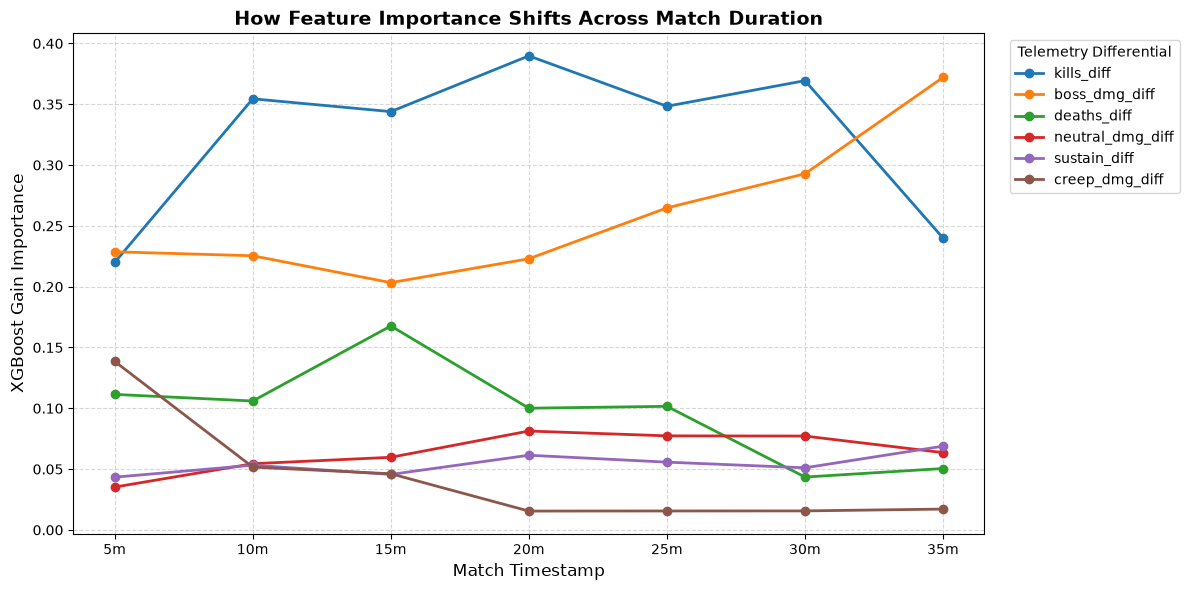

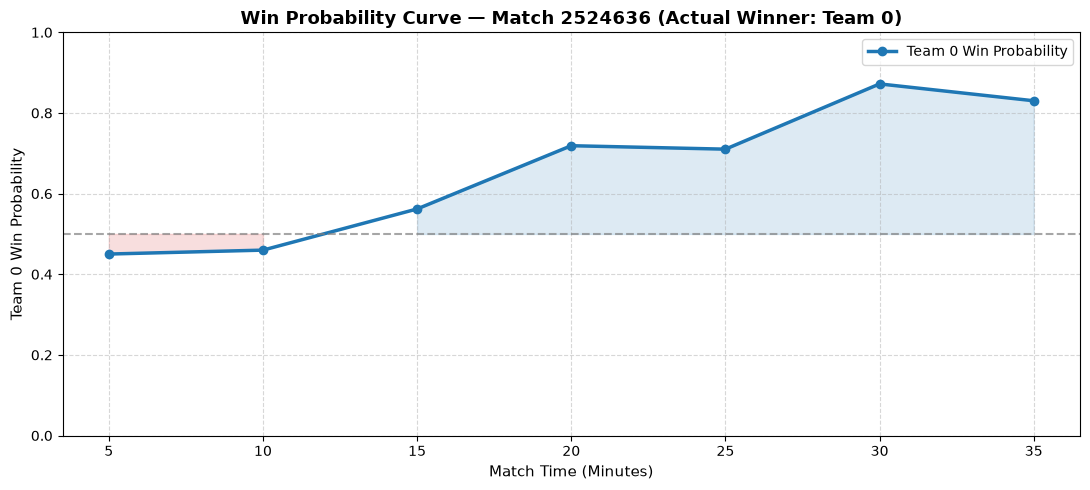

In [ ]:
# con_ts = duckdb.connect(db_path, read_only = True)

df_ts = con.execute(f"""
    WITH true_outcomes AS (
        SELECT DISTINCT
            m.match_info.match_id AS match_id,
            m.match_info.winning_team AS winning_team
        FROM match_metadata m
        WHERE m.match_info.winning_team IS NOT NULL
    ),
    team_snapshots AS (
        SELECT 
            match_id,
            time_stamp_s,
            team,
            SUM(tick_kills) AS kills,
            SUM(tick_deaths) AS deaths,
            SUM(tick_assists) AS assists,
            SUM(player_damage) AS player_damage,
            SUM(creep_damage) AS creep_damage,
            SUM(neutral_damage) AS neutral_damage,
            SUM(boss_damage) AS boss_damage,
            SUM(denies) AS denies,
            SUM(player_healing + self_healing) AS total_sustain,
            SUM(damage_absorbed) AS damage_absorbed,
            SUM(player_damage_taken) AS damage_taken,
            SUM(shots_hit) AS shots_hit,
            SUM(shots_missed) AS shots_missed,
        FROM read_parquet(?)
        WHERE time_stamp_s > 0
        GROUP BY match_id, time_stamp_s, team
    )
    SELECT 
        t0.match_id,
        t0.time_stamp_s,
        -- Economic & Objective Differentials (Team 0 minus Team 1)
        (t0.creep_damage - t1.creep_damage) AS creep_dmg_diff,
        (t0.neutral_damage - t1.neutral_damage) AS neutral_dmg_diff,
        (t0.boss_damage - t1.boss_damage) AS boss_dmg_diff,
        (t0.denies - t1.denies) AS denies_diff,
        
        -- Combat Differentials
        (t0.kills - t1.kills) AS kills_diff,
        (t0.deaths - t1.deaths) AS deaths_diff,
        (t0.assists - t1.assists) AS assists_diff,
        (t0.player_damage - t1.player_damage) AS player_dmg_diff,
        
        -- Sustain & Mitigation Differentials
        (t0.total_sustain - t1.total_sustain) AS sustain_diff,
        (t0.damage_absorbed - t1.damage_absorbed) AS dmg_absorbed_diff,
        (CAST(t0.damage_absorbed AS FLOAT) / NULLIF(t0.damage_taken, 0)) - 
        (CAST(t1.damage_absorbed AS FLOAT) / NULLIF(t1.damage_taken, 0)) AS mitigation_ratio_diff,
        
        -- Mechanical Accuracy Differential
        (CAST(t0.shots_hit AS FLOAT) / NULLIF(t0.shots_hit + t0.shots_missed, 0)) - 
        (CAST(t1.shots_hit AS FLOAT) / NULLIF(t1.shots_hit + t1.shots_missed, 0)) AS accuracy_diff,
        
        -- Ground Truth Label (1 if Team 0 won, 0 if Team 1 won)
        CASE WHEN o.winning_team = 0 THEN 1 ELSE 0 END AS label
    FROM team_snapshots t0
    JOIN team_snapshots t1 
        ON t0.match_id = t1.match_id 
        AND t0.time_stamp_s = t1.time_stamp_s 
        AND t0.team = 0 
        AND t1.team = 1
    JOIN true_outcomes o 
        ON t0.match_id = o.match_id
    ORDER BY t0.match_id, t0.time_stamp_s
""", [parquet_files]).df()

feature_cols = [
    'creep_dmg_diff', 'neutral_dmg_diff', 'boss_dmg_diff',
    'denies_diff', 'kills_diff', 'deaths_diff', 'assists_diff',
    'player_dmg_diff', 'sustain_diff', 'dmg_absorbed_diff',
    'mitigation_ratio_diff', 'accuracy_diff'
]

timestamps = [300, 600, 900, 1200, 1500, 1800, 2100]
models = {}
results = []
importance_over_time = {}

print("\n--- Training Timestamp-Specific XGBoost Models ---")
for t_sec in timestamps:
    df_slice = df_ts[df_ts['time_stamp_s'] == t_sec].dropna(subset = feature_cols + ['label'])
    
    if len(df_slice) < 100:
        print(f"Skipping {t_sec // 60}m: insufficient match sample size ({len(df_slice)}).")
        continue

    X = df_slice[feature_cols]
    y = df_slice['label']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size = 0.2, random_state = 42, stratify = y
    )

    clf = XGBClassifier(
        n_estimators = 150,
        max_depth = 3,
        learning_rate = 0.05,
        subsample = 0.8,
        colsample_bytree = 0.8,
        random_state = 42,
        eval_metric = 'logloss'
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    ll = log_loss(y_test, y_prob)

    models[t_sec] = clf
    importance_over_time[f"{t_sec // 60}m"] = dict(zip(feature_cols, clf.feature_importances_))
    results.append({
        'Minute': t_sec // 60,
        'Matches': len(df_slice),
        'Accuracy (%)': round(acc * 100, 2),
        'ROC-AUC': round(auc, 4),
        'Log-Loss': round(ll, 4)
    })

df_results = pd.DataFrame(results)
print("\n--- Model Performance by Match Timestamp ---")
print(df_results.to_string(index = False))

# Visualize Feature Importance Shifts Across Game Phases
df_imp = pd.DataFrame(importance_over_time)
top_features = df_imp.mean(axis = 1).sort_values(ascending = False).head(6).index

plt.figure(figsize = (12, 6))
for feat in top_features:
    plt.plot(df_imp.columns, df_imp.loc[feat], marker = 'o', linewidth = 2, label = feat)

plt.title('How Feature Importance Shifts Across Match Duration', fontsize = 14, fontweight = 'bold')
plt.xlabel('Match Timestamp', fontsize = 12)
plt.ylabel('XGBoost Gain Importance', fontsize = 12)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.legend(title = 'Telemetry Differential', bbox_to_anchor = (1.02, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

# Plot Live Win Probability Trajectory for a Random Test Match
test_match_id = X_test.index[0]
sample_id = df_ts.loc[test_match_id, 'match_id']
match_data = df_ts[df_ts['match_id'] == sample_id].sort_values('time_stamp_s')
actual_winner = "Team 0" if match_data['label'].iloc[0] == 1 else "Team 1"

mins, probs = [], []
for _, row in match_data.iterrows():
    t = row['time_stamp_s']
    if t in models:
        prob = models[t].predict_proba(row[feature_cols].values.reshape(1, -1))[0][1]
        mins.append(t / 60)
        probs.append(prob)

plt.figure(figsize=(11, 5))
plt.plot(mins, probs, marker='o', color='#1f77b4', linewidth=2.5, label='Team 0 Win Probability')
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.7)
plt.fill_between(mins, 0.5, probs, where=(np.array(probs) >= 0.5), color='#1f77b4', alpha=0.15)
plt.fill_between(mins, 0.5, probs, where=(np.array(probs) < 0.5), color='#d62728', alpha=0.15)
plt.title(f'Win Probability Curve — Match {sample_id} (Actual Winner: {actual_winner})', fontsize=13, fontweight='bold')
plt.xlabel('Match Time (Minutes)', fontsize=11)
plt.ylabel('Team 0 Win Probability', fontsize=11)
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()